### Rechteckschoner – Lösung Schritt für Schritt

*30. Bundeswettbewerb Informatik (2011), 1. Runde, Junioraufgabe 1*

Als eine ältere Mitschülerin von den letzten Zweitrundenaufgaben erzählte, hatte Moni die Idee zu einem eigenen
Bildschirmschoner: Gezeichnet werden soll ein Rechteck, das zwei Rechtecke enthält, die jeweils wieder zwei Rechtecke
enthalten usw. Damit das nett aussieht, soll bei der Rechteckschachtelung der Zufall eine sinnvolle Rolle spielen, und ein
enthaltenes Rechteck soll sich nicht nur in der Größe von dem es unmittelbar enthaltenden Rechteck unterscheiden.

Nach dem Aufbau soll das fertige Rechteckschachtelbild immer wieder so aktualisiert werden, dass mal das eine, mal das andere
Rechteck (evtl. mit allen enthaltenen Rechtecken) sein Aussehen verändert.

#### Junioraufgabe 1

Entwickle einen solchen „Rechteckschoner“. Demonstriere seine Funktion an mindestens drei verschiedenen
Rechteckschachtelbildern mit jeweils zwei Veränderungen.

Beispieldaten gibt es zu dieser Aufgabe nicht.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Baumstruktur:** Ein Rechteck enthält zwei Rechtecke, die jeweils wieder zwei enthalten. Das ist ein **binärer Baum**: Jedes Rechteck („Knoten“) hat höchstens zwei Kinder.
  Wir speichern ein Rechteck als `dict` (Wörterbuch) mit seinen Eigenschaften und der Liste seiner Kinder.
- **Rekursion:** Das Erzeugen, Zeichnen und Verändern eines Rechtecks ruft jeweils sich selbst für die Kinder auf. Eine Rekursion braucht einen **Abbruch**: Hier wird ein Rechteck nicht mehr geteilt, wenn es zu klein ist.
- **Zufall:** Die Teilung, die Farben und die Liniendicken sind zufällig (`random`). Mit `random.seed(zahl)` kann man das Bild reproduzieren.
- **Teile eines Baums verändern:** Zur Aktualisierung wählt man zufällig einen Weg nach unten (immer eines der Kinder) und gestaltet das Rechteck, an dem man ankommt, neu (samt seiner Kinder). Der Rest des Bildes bleibt gleich.
- **Kopie eines ganzen Baums:** Mit `copy.deepcopy` kopiert man einen Baum samt aller Kinder, damit man „vorher“ und „nachher“ vergleichen kann.

**Nützliche Funktionen und Bibliotheken**
- `import random`: `randint`, `choice`, `random`, `seed`
- `import copy`: `copy.deepcopy`
- `matplotlib.pyplot`: `add_patch(plt.Rectangle(...))`, `subplots`
- Für die echte Animation (nicht nötig): `matplotlib.animation.FuncAnimation`

## Die Idee

**Ein Rechteck** hat eine Position `(x, y)`, eine Breite `b`, eine Höhe `h`, eine Farbe, eine Liniendicke und eine Liste `kinder` (leer oder mit zwei Rechtecken).

**Aufbau (rekursiv).** Wir erzeugen ein großes Rechteck. Es teilt sich selbst auf, solange es groß genug ist:

1. Das Rechteck wird an seiner **längeren Seite** geteilt (so entstehen keine extrem schmalen Streifen).
2. Der Teilungspunkt liegt zufällig zwischen einem Viertel und drei Vierteln der Länge, damit jedes Kind mindestens ein Viertel der Länge bekommt.
3. Zwischen allen Kanten bleibt ein **Abstand** von 5 Pixeln. So überlappen sich die Kinder nicht, und sie liegen innerhalb des Elternrechtecks.
4. Ist die **kürzere** Seite kleiner als 30 Pixel, wird nicht mehr geteilt (Abbruch der Rekursion).

**Aktualisieren.** Wir wählen einen zufälligen Weg im Baum von der Wurzel nach unten. An jedem Rechteck mit Kindern geht es mit einer Wahrscheinlichkeit von 40 % nicht weiter: Dieses Rechteck bekommt dann neue Farbe, neue Dicke und
einen neuen Aufbau seiner Kinder. Sonst gehen wir zu einem zufälligen Kind. Das ganze Bild verändert sich nie auf einmal (die Wurzel wird nicht ersetzt, wenn sie Kinder hat).

## Schritt 1: Ein Rechteck und seine Kinder

`neues_rechteck(x, y, b, h)` erzeugt ein Rechteck mit zufälligen Eigenschaften und ruft `erzeuge_kinder` auf. `erzeuge_kinder` entscheidet, ob und wie das Rechteck geteilt wird, und ruft für die beiden Teile wieder
`neues_rechteck` auf: Das ist die Rekursion. Die Zufallszahlen für die Teilung kommen aus `random.randint(a, b)` (ganze Zahl von a bis b).

In `erzeuge_kinder` gibt es zwei Fälle: Das Rechteck ist **höher als breit** (`h > b`): dann teilen wir nach oben und unten, das erste Kind bekommt die Höhe `r`. Sonst teilen wir nach links und rechts.
Die Zahl `platz` ist die Länge, die nach Abzug der drei Abstände (außen, Mitte, außen) übrig bleibt.

In [ ]:
import random

ABSTAND = 5                                  # Abstand zwischen den Kanten
KLEINSTE_SEITE = 30                          # kleinere Rechtecke werden nicht mehr geteilt


def zufallsfarbe():
    return (random.random() * 0.8, random.random() * 0.8, random.random() * 0.8)


def neues_rechteck(x, y, b, h):
    rechteck = {'x': x, 'y': y, 'b': b, 'h': h,
                'farbe': zufallsfarbe(), 'dicke': random.randint(1, 3), 'kinder': []}
    erzeuge_kinder(rechteck)
    return rechteck


def erzeuge_kinder(rechteck):
    x = rechteck['x']
    y = rechteck['y']
    b = rechteck['b']
    h = rechteck['h']
    rechteck['kinder'] = []
    if min(b, h) < KLEINSTE_SEITE:
        return                                   # zu klein: keine Kinder
    if h > b:
        platz = h - 3 * ABSTAND
        r = random.randint(platz // 4, 3 * platz // 4)          # Höhe des ersten Kindes
        kind1 = neues_rechteck(x + ABSTAND, y + ABSTAND, b - 2 * ABSTAND, r)
        kind2 = neues_rechteck(x + ABSTAND, y + r + 2 * ABSTAND, b - 2 * ABSTAND, h - r - 3 * ABSTAND)
    else:
        platz = b - 3 * ABSTAND
        r = random.randint(platz // 4, 3 * platz // 4)          # Breite des ersten Kindes
        kind1 = neues_rechteck(x + ABSTAND, y + ABSTAND, r, h - 2 * ABSTAND)
        kind2 = neues_rechteck(x + r + 2 * ABSTAND, y + ABSTAND, b - r - 3 * ABSTAND, h - 2 * ABSTAND)
    rechteck['kinder'] = [kind1, kind2]


def zaehle(rechteck):
    summe = 1
    for kind in rechteck['kinder']:
        summe = summe + zaehle(kind)
    return summe


random.seed(1)
bild = neues_rechteck(0, 0, 400, 300)
print('Das Bild besteht aus', zaehle(bild), 'Rechtecken.')
print('Wurzel:', {k: v for k, v in bild.items() if k != 'kinder'})
print('Das erste Kind der Wurzel:', {k: v for k, v in bild['kinder'][0].items() if k != 'kinder'})

Das Bild besteht aus 85 Rechtecken.
Wurzel: {'x': 0, 'y': 0, 'b': 400, 'h': 300, 'farbe': (0.10749139528992098, 0.6779469895497862, 0.6110196951812913), 'dicke': 2}
Das erste Kind der Wurzel: {'x': 5, 'y': 5, 'b': 126, 'h': 290, 'farbe': (0.3963480696735528, 0.35959285183099055, 0.5212743781782104), 'dicke': 1}


Die Wurzel (400 × 300) wird an der längeren Seite (der Breite) geteilt. Das erste Kind beginnt 5 Pixel vom linken und oberen Rand und ist 290 Pixel hoch (300 − 2 · 5).

## Schritt 2: Prüfen, ob alles stimmt

Eine eigene Funktion kontrolliert die Regeln der Aufgabe für den ganzen Baum (rekursiv für alle Kinder):

- Alle Seitenlängen sind **positiv**.
- Jedes Kind liegt **vollständig innerhalb** seines Elternrechtecks.
- Die beiden Kinder **überlappen sich nicht**. Das prüfen wir mit den vier Vergleichen „liegt ganz links/rechts/oben/unten“.
- Der Abstand beträgt mindestens `ABSTAND` zwischen allen Kanten.

In [ ]:
def ist_korrekt(rechteck):
    if rechteck['b'] <= 0 or rechteck['h'] <= 0:
        return False
    kinder = rechteck['kinder']
    for kind in kinder:
        innen = (kind['x'] >= rechteck['x'] + ABSTAND and kind['y'] >= rechteck['y'] + ABSTAND
                 and kind['x'] + kind['b'] <= rechteck['x'] + rechteck['b'] - ABSTAND
                 and kind['y'] + kind['h'] <= rechteck['y'] + rechteck['h'] - ABSTAND)
        if not innen or not ist_korrekt(kind):
            return False
    if len(kinder) == 2:
        a = kinder[0]
        c = kinder[1]
        getrennt = (a['x'] + a['b'] + ABSTAND <= c['x'] or c['x'] + c['b'] + ABSTAND <= a['x']
                    or a['y'] + a['h'] + ABSTAND <= c['y'] or c['y'] + c['h'] + ABSTAND <= a['y'])
        if not getrennt:
            return False
    return True


print('Das Bild von oben ist korrekt:', ist_korrekt(bild))

random.seed(2)
alle_gut = True
for versuch in range(300):
    b = random.randint(40, 600)
    h = random.randint(40, 600)
    if not ist_korrekt(neues_rechteck(0, 0, b, h)):
        alle_gut = False
print('300 zufällige Bilder verschiedener Größe sind alle korrekt:', alle_gut)

Das Bild von oben ist korrekt: True
300 zufällige Bilder verschiedener Größe sind alle korrekt: True


## Schritt 3: Zeichnen

`zeichne(rechteck, achse)` zeichnet das Rechteck als Umriss (`fill=False`) in seiner Farbe und Liniendicke und ruft sich dann für die Kinder auf (Rekursion). Mit `plt.Rectangle((x, y), breite, hoehe, ...)` erzeugt man ein Rechteck,
`achse.add_patch(...)` fügt es zum Bild hinzu.

Wir geben der Zeichnung optional ein markiertes Rechteck mit (`markiert`): Es bekommt einen roten gestrichelten Rahmen, damit man sieht, wo etwas **geändert** wurde.
Die y-Achse drehen wir mit `invert_yaxis()` um, damit der Ursprung wie bei Bildschirmkoordinaten oben links liegt.

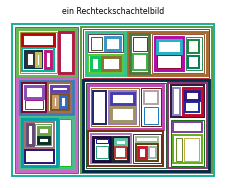

In [ ]:
import matplotlib.pyplot as plt


def zeichne(rechteck, achse):
    achse.add_patch(plt.Rectangle((rechteck['x'], rechteck['y']), rechteck['b'], rechteck['h'],
                                  fill=False, edgecolor=rechteck['farbe'], linewidth=rechteck['dicke']))
    for kind in rechteck['kinder']:
        zeichne(kind, achse)


def zeige(rechteck, achse, titel, markiert=None):
    zeichne(rechteck, achse)
    if markiert is not None:
        x, y, b, h = markiert
        achse.add_patch(plt.Rectangle((x - 2, y - 2), b + 4, h + 4, fill=False, edgecolor='red', linestyle='--', linewidth=1))
    achse.set_xlim(-10, rechteck['b'] + 10)
    achse.set_ylim(rechteck['h'] + 10, -10)         # y nach unten, wie auf dem Bildschirm
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=8)
    achse.axis('off')


bild_achse = plt.subplots(1, 1, figsize=(4, 3))
zeige(bild, bild_achse[1], 'ein Rechteckschachtelbild')
plt.show()

## Schritt 4: Aktualisieren

`aendere(rechteck, ist_wurzel)` wählt zufällig einen Weg nach unten und gestaltet an einem Rechteck alles neu (Farbe, Dicke, Kinder). Die Funktion gibt die Maße des geänderten Rechtecks zurück, damit wir es markieren können.

An der **Wurzel** geht es immer zu einem Kind weiter (sonst würde sich das ganze Bild ändern), an allen anderen Rechtecken mit Kindern hört der Weg mit 40 % Wahrscheinlichkeit auf. Rechtecke ohne Kinder werden immer neu gestaltet.
Die neuen Kinder (`erzeuge_kinder`) liegen wieder im selben Rechteck, ohne sich zu überlappen.

In [ ]:
def aendere(rechteck, ist_wurzel=True):
    kinder = rechteck['kinder']
    if len(kinder) == 0 or (not ist_wurzel and random.random() < 0.4):
        rechteck['farbe'] = zufallsfarbe()
        rechteck['dicke'] = random.randint(1, 3)
        erzeuge_kinder(rechteck)                    # neuer Aufbau darunter
        return (rechteck['x'], rechteck['y'], rechteck['b'], rechteck['h'])
    return aendere(random.choice(kinder), False)    # sonst weiter zu einem zufälligen Kind


random.seed(3)
probe = neues_rechteck(0, 0, 400, 300)
vorher = zaehle(probe)
gemacht = aendere(probe)
print('Geändertes Rechteck (x, y, b, h):', gemacht)
print('Rechtecke vorher:', vorher, ' nachher:', zaehle(probe), ' Bild korrekt:', ist_korrekt(probe))

Geändertes Rechteck (x, y, b, h): (355, 236, 20, 39)
Rechtecke vorher: 91  nachher: 91  Bild korrekt: True


## Schritt 5: Drei Bilder mit je zwei Veränderungen

Für jedes der drei Bilder (mit verschiedener Größe und anderem Startwert des Zufalls) zeichnen wir den Anfang, den Zustand nach der ersten und nach der zweiten Änderung. Dazu **kopieren** wir den Baum mit `copy.deepcopy`, damit
die früheren Bilder erhalten bleiben. Die geänderte Stelle ist rot gestrichelt umrandet. Bei jeder Änderung gilt: Nur ein Teil des Bildes verändert sich.

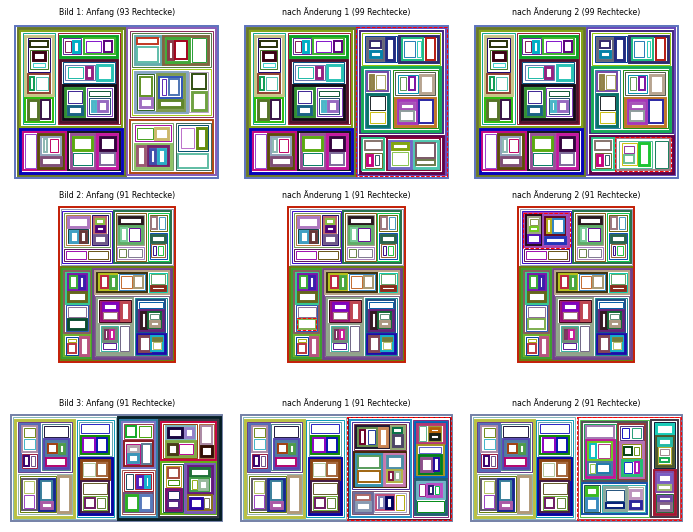

In [ ]:
import copy

bild_achsen = plt.subplots(3, 3, figsize=(10, 8))[1]
for zeile, (seed, b, h) in enumerate([(11, 400, 300), (22, 300, 400), (33, 500, 250)]):
    random.seed(seed)
    stand = neues_rechteck(0, 0, b, h)
    zeige(stand, bild_achsen[zeile][0], f'Bild {zeile + 1}: Anfang ({zaehle(stand)} Rechtecke)')
    for aenderung in (1, 2):
        stand = copy.deepcopy(stand)                       # den Zustand davor behalten wir im Bild links davon
        stelle = aendere(stand)
        zeige(stand, bild_achsen[zeile][aenderung], f'nach Änderung {aenderung} ({zaehle(stand)} Rechtecke)', markiert=stelle)
        assert ist_korrekt(stand)
plt.tight_layout()
plt.show()

Man sieht: Bei jeder Änderung wird nur ein Teil des Bildes (das rot umrandete Rechteck mit allem, was darin liegt) neu gestaltet. Der Rest bleibt gleich. Die Bilder bleiben korrekt: nichts überlappt, nichts ragt über den Rand.

## Für Neugierige: Der eigentliche Bildschirmschoner

Ein echter Bildschirmschoner ändert das Bild immer wieder. Mit einer Schleife aus `aendere` und Neuzeichnen und einer kurzen Pause wäre das eine Animation. In einem Jupyter-Notebook geht das zum Beispiel so (hier nicht ausgeführt,
weil die Anzeige im Notebook ein eigenes Fenster braucht):

```python
import time
from IPython.display import clear_output

bild = neues_rechteck(0, 0, 400, 300)
for runde in range(30):
    clear_output(wait=True)
    figur, achse = plt.subplots(figsize=(4, 3))
    zeige(bild, achse, f'Runde {runde}')
    plt.show()
    time.sleep(0.5)
    aendere(bild)
```

Wer mehr will, kann das Programm erweitern: Rechtecke mit Füllfarbe, Hintergrund schwarz, Rechtecke wachsen langsam statt sich plötzlich zu ändern, oder drei statt zwei Kinder pro Rechteck.
Eine Möglichkeit ist auch, `aendere` mehrere Äste gleichzeitig verändern zu lassen.